In [57]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [59]:
from cyclical_MCMC import load_fn, load_data
from plotting import plot_distributions, plot_VY, plot_VYconv

# Load data and draws

In [65]:
Y, dY, dY_pd, Y_indx, T, VIX_df = load_data('data/SP500.csv', VIX_path='data/VIXCLS.csv')
draws = load_fn('saved/draws_basic')

Data from 2016-09-19 00:00:00 to 2026-09-17 00:00:00


In [5]:
N = 8
G = 10_000

# V vs VIX vs ARCH

In [88]:
from arch import arch_model

# y: daglige afkast i procent (pakken forventer procent, ikke brøk)
am = arch_model(dY, mean="Constant", vol="GARCH", p=10, q=10, dist="t")
res = am.fit(disp="off")
print(res.summary())

# conditional volatilitet, annualiseret, så den kan sammenlignes med VIX
vol_ann = res.conditional_volatility * 252**0.5

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                            y   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3142.30
Distribution:      Standardized Student's t   AIC:                           6330.61
Method:                  Maximum Likelihood   BIC:                           6464.67
                                              No. Observations:                 2512
Date:                      Thu, Nov 19 2026   Df Residuals:                     2511
Time:                              15:33:00   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

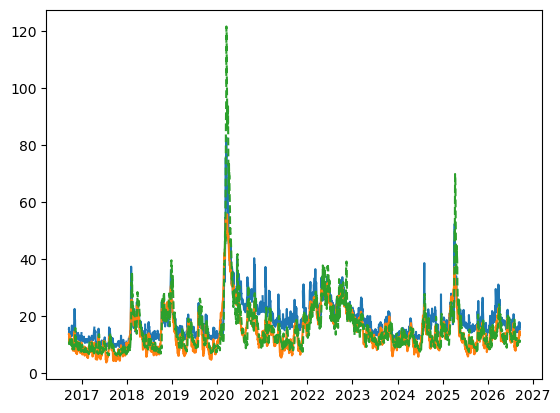

In [89]:
f, ax = plt.subplots()

ax.plot(VIX_df)
ax.plot(Y_indx, np.sqrt(252*draws.V.mean(axis=(0,2))))
ax.plot(Y_indx[1:], vol_ann, ls='--')

In [90]:
VIX_df.std()

VIXCLS    7.25513
dtype: float64

In [91]:
np.sqrt(252*draws.V.mean(axis=(0,2))).std()

np.float64(7.378191663882624)

In [109]:
np.corrcoef(VIX_df.loc[Y_indx][1:].to_numpy().flatten(), dY)

array([[ 1.        , -0.17218793],
       [-0.17218793,  1.        ]])

array([15.92, 13.3 , 12.02, ..., 17.2 , 17.71, 15.44], shape=(2512,))

# Marginal Distributions

In [6]:
burnin = G // 2

In [7]:
xlim_dict = {
    #(0,1):[1,6],
    #(0,2):[0.025,0.09],
    #(1,0):[-0.8,-0.5],
    #(1,1):[-0.01,0.15]
}

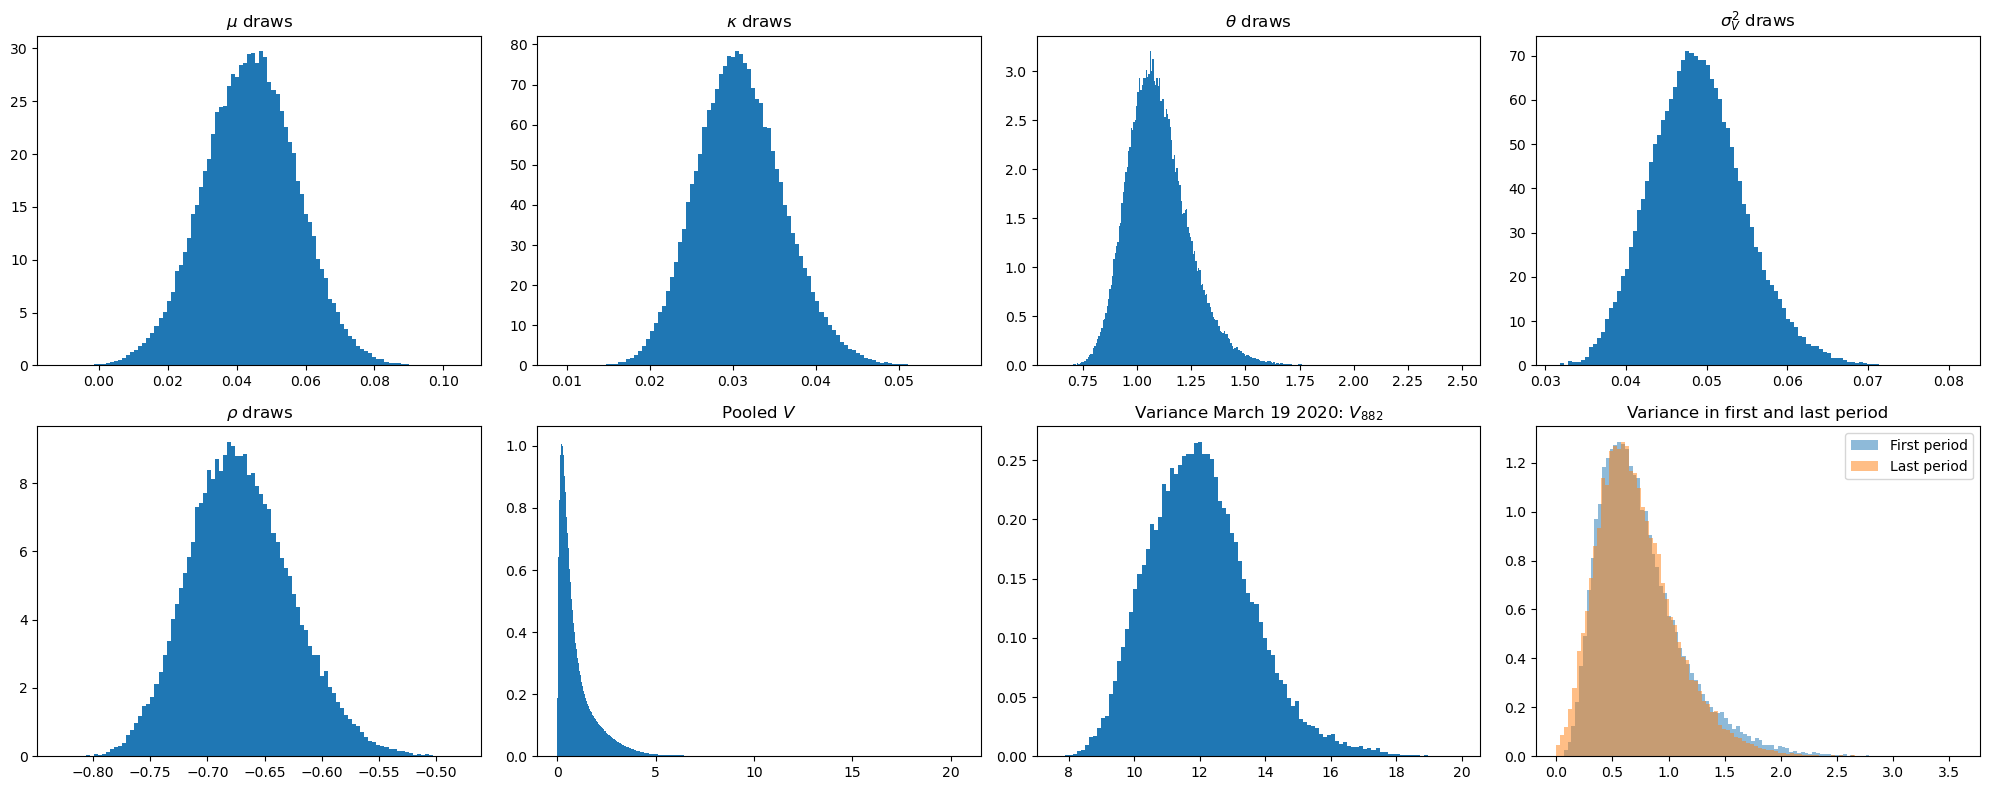

In [8]:
plot_distributions(draws, G, burnin=burnin, xlim_dict=xlim_dict, bins_=[100, 100, 300, 100, 100, 1000, 100, 100])

In [51]:
# import numpy as np, pandas as pd, matplotlib.pyplot as plt
# from matplotlib.gridspec import GridSpec
# from matplotlib.ticker import MaxNLocator, FormatStrFormatter
# from scipy.ndimage import gaussian_filter
# plt.rcParams['mathtext.fontset'] = 'cm'

# NAMES  = ['mu', 'kappa', 'theta', 'sigma_sq_V', 'rho']
# LABELS = {'mu': r'$\mu$', 'kappa': r'$\kappa$', 'theta': r'$\theta$', 'sigma_sq_V': r'$\sigma_V^2$', 'rho': r'$\rho$'}


# def smoothed_density(x, y, bins=60, smooth=2.0, q=(0.1, 99.9)):
#     """2D-histogram (tæthed) udglattet med Gauss-filter (smooth = sigma målt i bins).
#     Returnerer bin-midtpunkter xc, yc og tæthed D (len(xc), len(yc)), renormaliseret til integral 1."""
#     rng = [np.percentile(x, q), np.percentile(y, q)]
#     H, xe, ye = np.histogram2d(x, y, bins=bins, range=rng)
#     if smooth > 0:
#         H = gaussian_filter(H, smooth, mode='constant')
#     dx, dy = np.diff(xe)[0], np.diff(ye)[0]
#     D = H/(H.sum()*dx*dy)
#     return 0.5*(xe[:-1] + xe[1:]), 0.5*(ye[:-1] + ye[1:]), D


# def kde_density(x, y, n=100, max_pts=10000, q=(0.1, 99.9), seed=0):
#     """Gaussisk 2D-KDE (scipy.stats.gaussian_kde) på et n×n-gitter, som i Medium-artiklen.
#     Subsampler til max_pts punkter (KDE koster ~ n²·max_pts). Returnerer xx, yy, f (n×n)."""
#     from scipy.stats import gaussian_kde
#     rng = np.random.default_rng(seed)
#     if len(x) > max_pts:
#         i = rng.choice(len(x), max_pts, replace=False); x, y = x[i], y[i]
#     (x0, x1), (y0, y1) = np.percentile(x, q), np.percentile(y, q)
#     xx, yy = np.mgrid[x0:x1:n*1j, y0:y1:n*1j]
#     kernel = gaussian_kde(np.vstack([x, y]))
#     f = np.reshape(kernel(np.vstack([xx.ravel(), yy.ravel()])).T, xx.shape)
#     return xx, yy, f


# def _clean_ticks(ax, n=4, fmt='%.3g'):
#     """Få og pæne ticks på 3D-akserne, så tallene ikke ligger oven i hinanden."""
#     for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
#         axis.set_major_locator(MaxNLocator(nbins=n, prune=None))
#         axis.set_major_formatter(FormatStrFormatter(fmt))
#     ax.tick_params(axis='x', labelsize=8, pad=-2)
#     ax.tick_params(axis='y', labelsize=8, pad=-2)
#     ax.tick_params(axis='z', labelsize=8, pad=1)
#     for lab in ax.get_xticklabels(): lab.set_horizontalalignment('right')
#     for lab in ax.get_yticklabels(): lab.set_horizontalalignment('left')


# def corr_figure(pars, pair=('kappa', 'theta'), bins=60, smooth=2.0, elev=None, azim=None,
#                 style='kde_surface', alpha=0.9):
#     """Venstre: korrelationsmatrix. Højre: 3D-plot af den (udglattede) tæthed for ét par.
#        pars: DataFrame med kolonnerne mu, kappa, theta, sigma_sq_V, rho (poolede trækninger).
#        style='kde_surface': Gaussisk KDE som farvet surface (coolwarm, view 60/35) = første plot i Medium-artiklen
#        style='wireframe': Gaussisk KDE som wireframe (som i Medium-artiklen; bagsiden er synlig gennem nettet)
#        style='surface' : udglattet overflade (bagsiden kan ses, fordi overfladen er kontinuert)
#        style='bars'    : rå 3D-histogram (brug bins~25, smooth=0)"""
#     corr = pars[NAMES].corr()
#     a, b = pair

#     f = plt.figure(figsize=(12, 5.2))
#     gs = GridSpec(1, 3, figure=f, width_ratios=[1.4, 0.06, 1.9], wspace=0.35)

#     # venstre: korrelationsmatrix
#     ax = f.add_subplot(gs[0, 0]); cax = f.add_subplot(gs[0, 1])
#     im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
#     ax.set_xticks(range(5)); ax.set_xticklabels([LABELS[n] for n in NAMES])
#     ax.set_yticks(range(5)); ax.set_yticklabels([LABELS[n] for n in NAMES])
#     for i in range(5):
#         for j in range(5):
#             ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
#     f.colorbar(im, cax=cax)

#     # højre: 3D-tæthed
#     ax2 = f.add_subplot(gs[0, 2], projection='3d')
#     if style in ('kde_surface', 'wireframe'):
#         X, Y, D = kde_density(pars[a].to_numpy(), pars[b].to_numpy(), n=100)
#     if style == 'kde_surface':      # som første plot i 'Simple example of 2D density plots in python'
#         surf = ax2.plot_surface(X, Y, D, rstride=1, cstride=1, cmap='coolwarm', edgecolor='none')
#         f.colorbar(surf, ax=ax2, shrink=0.5, aspect=5, pad=-0.02, label='tæthed')
#     elif style == 'wireframe':
#         ax2.plot_wireframe(X, Y, D, rstride=3, cstride=3, color='C0', linewidth=0.6)
#     else:
#         xc, yc, D = smoothed_density(pars[a].to_numpy(), pars[b].to_numpy(), bins=bins, smooth=smooth)
#         X, Y = np.meshgrid(xc, yc, indexing='ij')
#     if style in ('kde_surface', 'wireframe'):
#         pass
#     elif style == 'surface':
#         ax2.plot_surface(X, Y, D, cmap='viridis', alpha=alpha, rstride=1, cstride=1,
#                          linewidth=0, antialiased=True, shade=True)
#         ax2.plot_wireframe(X, Y, D, rstride=8, cstride=8, color='k', linewidth=0.2, alpha=0.3)
#     else:
#         h = D.ravel(); hmax = h.max()
#         ax2.bar3d(X.ravel(), Y.ravel(), np.zeros_like(h), np.diff(xc)[0], np.diff(yc)[0], h,
#                   color=plt.cm.viridis(h/hmax), alpha=alpha, shade=True, linewidth=0.1, edgecolor='k')
#     ax2.set_xlabel(LABELS[a], labelpad=4); ax2.set_ylabel(LABELS[b], labelpad=4)
#     if style != 'kde_surface':      # her bærer colorbaren 'tæthed'-labelen
#         ax2.set_zlabel('tæthed', labelpad=-2)
#     ax2.set_zlim(0, D.max()*1.05)
#     d_elev, d_azim = (60, 35) if style == 'kde_surface' else (35, -55)
#     ax2.view_init(elev=d_elev if elev is None else elev, azim=d_azim if azim is None else azim)
#     _clean_ticks(ax2)
#     ax2.set_title(rf'corr = {corr.loc[a, b]:.2f}', fontsize=10)
#     return f

In [52]:
# corr_figure(pars)                          # KDE-surface, coolwarm (standard)
# corr_figure(pars, style='wireframe')       # artiklens andet plot
# corr_figure(pars, style='surface')         # udglattet histogram
# corr_figure(pars, elev=40, azim=-60)       # egen vinkel

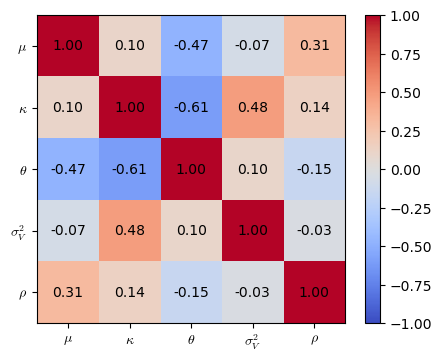

In [53]:
mu_ = draws.mu[:,burnin:].flatten()
kappa_ = draws.kappa[:,burnin:].flatten()
theta_ = (draws.kappatheta[:,burnin:]/draws.kappa[:,burnin:]).flatten()
sigma_sq_V_ = draws.sigma_sq_V[:,burnin:].flatten()
rho_ = draws.rho[:,burnin:].flatten()

# construct df
pars = pd.DataFrame({
    'mu':         mu_,
    'kappa':      kappa_,
    'theta':      theta_,
    'sigma_sq_V': sigma_sq_V_,
    'rho':        rho_,
})

# compute all correlations
corr = pars.corr()

# pd.plotting.scatter_matrix(pars, figsize=(8, 8),
#                            alpha=0.1, diagonal='hist', hist_kwds={'bins': 100});

labels = [r'$\mu$', r'$\kappa$', r'$\theta$', r'$\sigma_V^2$', r'$\rho$']

f, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(5)); ax.set_xticklabels(labels)
ax.set_yticks(range(5)); ax.set_yticklabels(labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
f.colorbar(im)

In [ ]:
pd.read_csv('data/VIXCLS.csv')

,observation_date,VIXCLS
0,1990-01-02,17.24
1,1990-01-03,18.19
2,1990-01-04,19.22
3,1990-01-05,20.11
4,1990-01-08,20.26
...,...,...
9616,2026-11-11,17.49
9617,2026-11-12,18.70
9618,2026-11-13,19.30
9619,2026-11-16,22.91


# Estimated Time Series of Variance

In [54]:
market_stress = [
    ['COVID-19 onset\nFeb 24 - May 5, 2020', '2020-02-24', '2020-05-04', 'red', (5,0.5)],
    ['FED rate hikes\nOct 2018 - Jan 2019', '2018-10-01', '2019-01-01', 'olive', (-3,0.5)]
]

vlines_stress = [
    ['Trump Tariffs\nApr 2, 2025', '2025-04-02', 'green', (200,0.5)],
    ['Russian Invasion of Ukraine\nMar 22, 2022', '2022-03-22', 'purple', (350,0.5)]
]

ylim = [-0.5,17.5]

In [55]:
plot_VY(draws, dY, Y_indx, 
        burnin=burnin, marked_intervals=market_stress, vlines=vlines_stress, plot_dY=False, ylim=ylim, filename='EstVTimeSeries')

TypeError: plot_VY() got multiple values for argument 'burnin'

In [ ]:
from convergence import Rhat_ess

In [ ]:
Rhat_list = []
ESS_list = []
var_list = []

for t in range(0, draws.V.shape[1]):
    print(t)
    Rhat, ESS, var = Rhat_ess(draws.V[:,t,:])
    Rhat_list.append(Rhat)
    ESS_list.append(ESS)
    var_list.append(var)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

In [ ]:
Rhat = np.array(Rhat_list)
ESS = np.array(ESS_list)

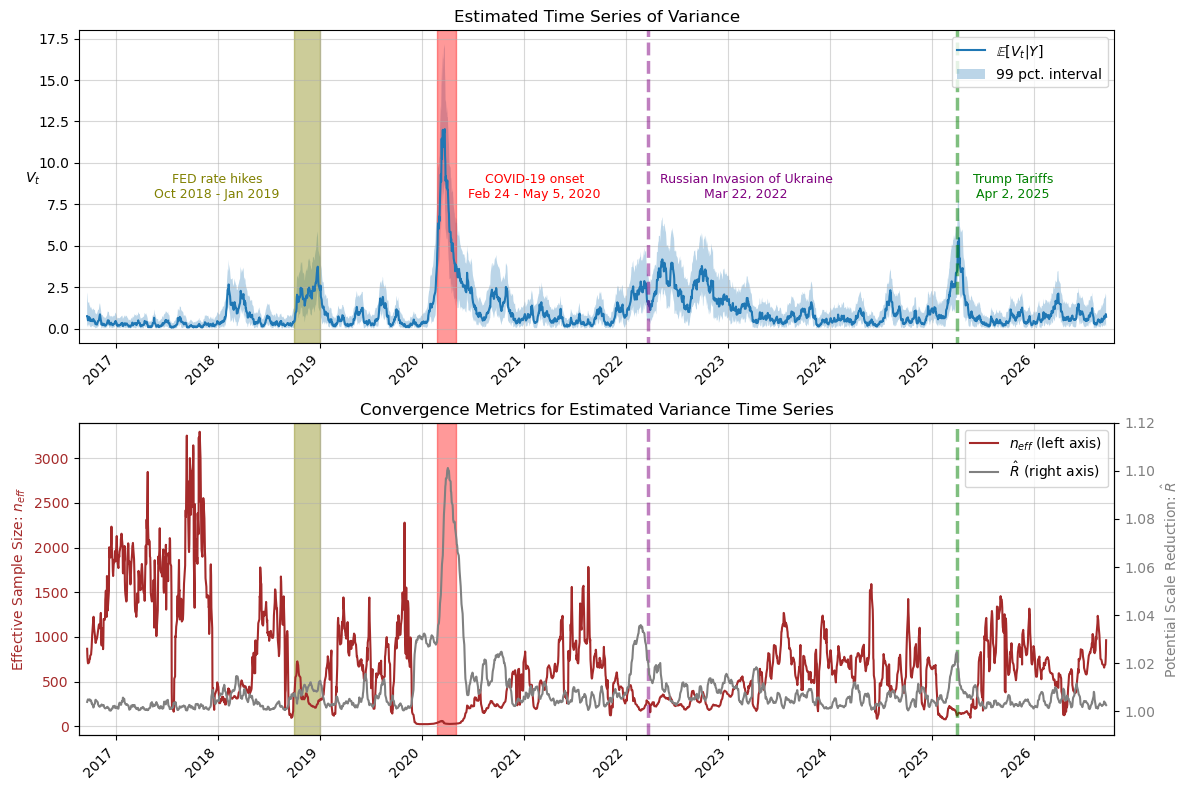

In [ ]:
plot_VYconv(draws, Rhat, ESS, Y_indx, burnin=burnin, marked_intervals=market_stress, vlines=vlines_stress, filename='EstVTimeSeries')

# Posterior Distribution of $\rho,\sigma^2_V$

In [ ]:
H, xedges, yedges = np.histogram2d(x, y, bins=25)

# søjlernes nederste hjørne og størrelse
xpos, ypos = np.meshgrid(xedges[:-1], yedges[:-1], indexing='ij')
xpos, ypos = xpos.ravel(), ypos.ravel()
dx = np.diff(xedges)[0]
dy = np.diff(yedges)[0]
dz = H.ravel()

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection='3d')
ax.bar3d(xpos, ypos, np.zeros_like(dz), dx, dy, dz, shade=True)
ax.set_xlabel(r'$\rho$')
ax.set_ylabel(r'$\sigma_V^2$')
ax.set_zlabel('antal')
plt.show()

NameError: name 'x' is not defined

# Trace plots

Text(0.5, 1.0, 'Variance at July 3th, 2020')

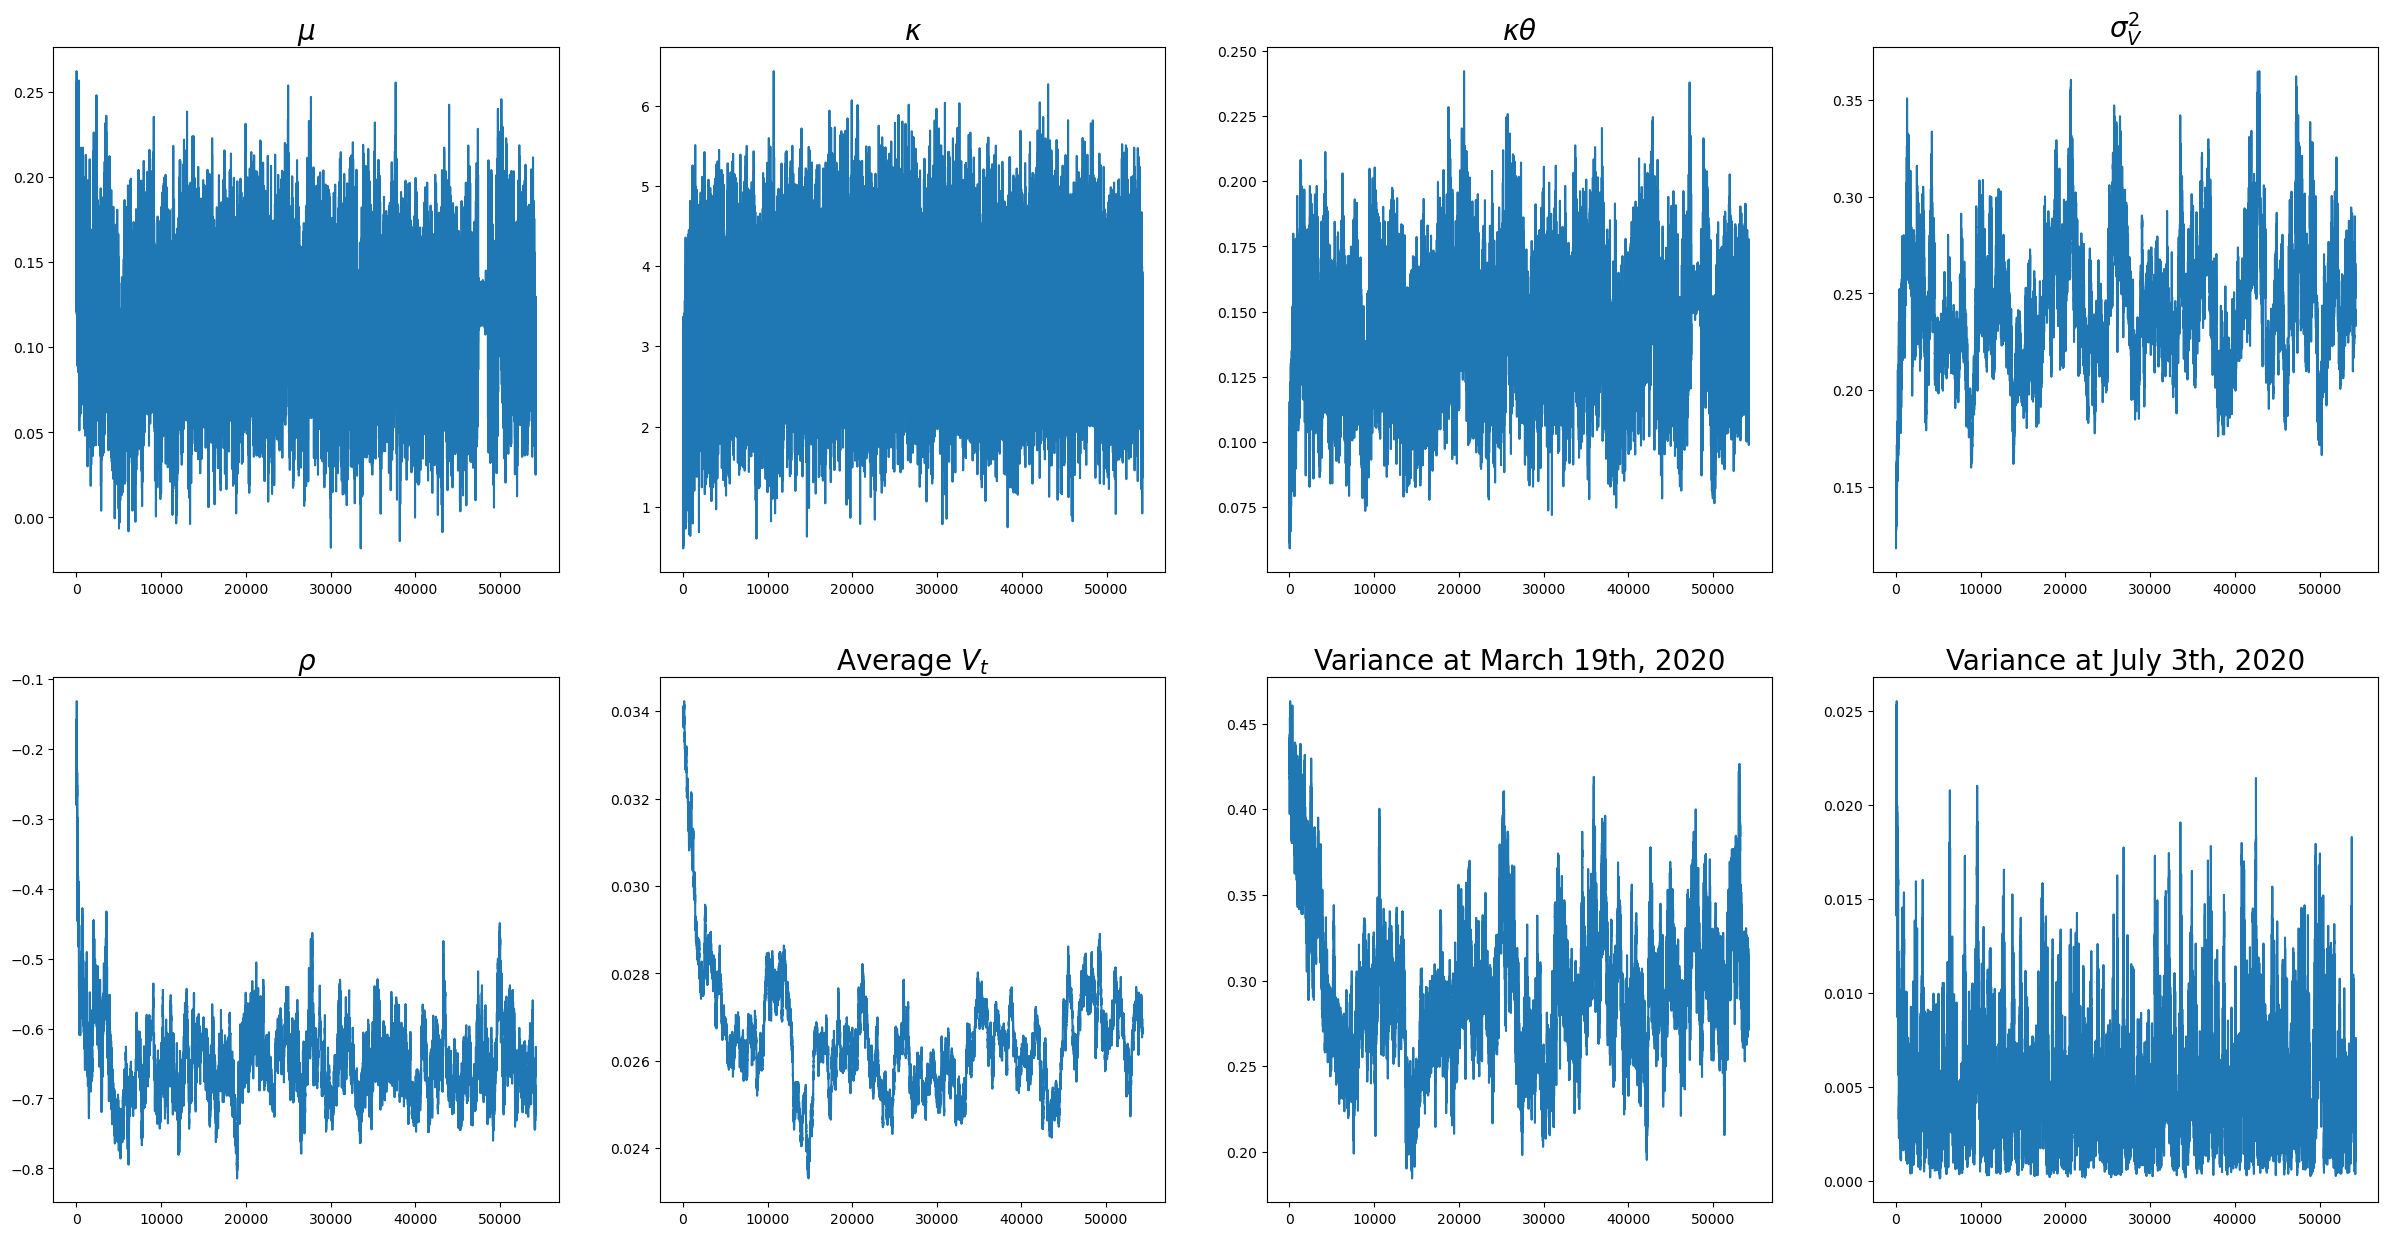

In [ ]:
f, ax = plt.subplots(2,4, figsize=(30,15))

ax[0,0].plot(draws['mu_draws'][burnin:])
ax[0,0].set_title(r'$\mu$', fontsize=20)

ax[0,1].plot(draws['kappa_draws'][burnin:])
ax[0,1].set_title(r'$\kappa$', fontsize=20)

ax[0,2].plot(draws['kappatheta_draws'][burnin:])
ax[0,2].set_title(r'$\kappa \theta$', fontsize=20)

ax[0,3].plot(draws['sigma_sq_V_draws'][burnin:])
ax[0,3].set_title(r'$\sigma^2_V$', fontsize=20)

ax[1,0].plot(draws['rho_draws'][burnin:])
ax[1,0].set_title(r'$\rho$', fontsize=20)

ax[1,1].plot(draws['V_draws'][burnin:].mean(axis=0))
ax[1,1].set_title(r'Average $V_t$', fontsize=20)
# V_lo, V_hi = np.percentile(draws['V_draws'][burnin:], [2.5, 97.5], axis=0)
# ax[1,1].fill_between(np.arange(len(V_lo)), V_lo, V_hi, alpha=0.5, label='95 pct. band')

ax[1,2].plot(draws['V_draws'][882, burnin:])
ax[1,2].set_title(r'Variance at March 19th, 2020', fontsize=20)

random_period = 701
ax[1,3].plot(draws['V_draws'][random_period, burnin:])
ax[1,3].set_title(r'Variance at July 3th, 2020', fontsize=20)

In [ ]:
SP500_df.index[random_period]

Timestamp('2019-07-03 00:00:00')

# Acceptance rates

In [ ]:
V_intervals = ([None, 500,], [500, 1000], [1000, 1500], [1500, 2000], [2000, None])

In [ ]:
cum_acceptrate_rho = np.cumsum(accepts['rho']) / np.arange(1,1+len(accepts['rho']))
cum_acceptrate_sigma_sq_V = np.cumsum(accepts['sigma_sq_V']) / np.arange(1,1+len(accepts['sigma_sq_V']))

cum_acceptrates_V = np.zeros_like(accepts['V']) + np.nan
for row in range(accepts['V'].shape[0]):
    cum_acceptrates_V[row] = np.cumsum(accepts['V'][row]) / np.arange(1,1+len(accepts['V'][row]))

cum_acceptrates_V_mean = cum_acceptrates_V.mean(axis=0)
cum_acceptrates_V_lo, cum_acceptrates_V_hi = np.percentile(cum_acceptrates_V, [2.5, 97.5], axis=0)
cum_acceptrates_V_min, cum_acceptrates_V_max = np.percentile(cum_acceptrates_V, [0.0, 100], axis=0)

f, ax = plt.subplots()

ax.plot(cum_acceptrate_rho[burnin:], label=r'$\rho$')
ax.plot(cum_acceptrate_sigma_sq_V[burnin:], label=r'$\sigma^2_V$')
ax.plot(cum_acceptrates_V_mean[burnin:], color='black', ls='--', label=r'Average for $\{V_t \}_{t=1}^{T}$')
ax.fill_between(np.arange(len(cum_acceptrates_V_mean[burnin:])), cum_acceptrates_V_min[burnin:], cum_acceptrates_V_max[burnin:],
                 alpha=0.3, color='gray', label=r'min-max bounds for $\{V_t \}_{t=1}^{T}$')
ax.fill_between(np.arange(len(cum_acceptrates_V_mean[burnin:])), cum_acceptrates_V_lo[burnin:], cum_acceptrates_V_hi[burnin:],
                 alpha=0.3, color='blue', label=r'95 pct. bounds for $\{V_t \}_{t=1}^{T}$')
ax.set_xlabel('Cycle')
ax.set_ylabel('Cumulative Average Acceptance Rate')
ax.grid()

ax.legend();

KeyboardInterrupt: 